In [1]:
%pip -q install -U ultralytics kaggle pyyaml

import os
import platform
import subprocess
from pathlib import Path
from collections import Counter

import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Runtime:", platform.platform())
print("CUDA available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.198
Runtime: Linux-6.6.159+-x86_64-with-glibc2.39
CUDA available: False


In [2]:
from google.colab import files

uploaded = files.upload()
if "kaggle.json" not in uploaded:
    raise FileNotFoundError("Upload the Kaggle API token named kaggle.json.")

KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
KAGGLE_TOKEN = KAGGLE_DIR / "kaggle.json"
KAGGLE_TOKEN.write_bytes(uploaded["kaggle.json"])
os.chmod(KAGGLE_TOKEN, 0o600)

check = subprocess.run(
    ["kaggle", "datasets", "list", "-s", "rdd-2022"],
    capture_output=True,
    text=True
)
if check.returncode != 0:
    raise RuntimeError(
        "Kaggle authentication failed. Verify kaggle.json and dataset access.\n"
        + check.stderr[-2000:]
    )

print("Kaggle authentication successful.")

Saving kaggle.json to kaggle.json
Kaggle authentication successful.


In [3]:
DATA_DOWNLOAD_DIR = Path("/content/RDD2022_Kaggle_Download")
DATA_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

download = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "aliabdelmenam/rdd-2022",
        "-p", str(DATA_DOWNLOAD_DIR),
        "--unzip"
    ],
    capture_output=True,
    text=True
)

print(download.stdout[-3000:])
if download.returncode != 0:
    raise RuntimeError("RDD2022 download failed.\n" + download.stderr[-3000:])

SOURCE_ROOT = DATA_DOWNLOAD_DIR / "RDD_SPLIT"
if not SOURCE_ROOT.exists():
    candidates = list(DATA_DOWNLOAD_DIR.rglob("RDD_SPLIT"))
    if not candidates:
        raise FileNotFoundError(
            f"RDD_SPLIT was not found after extraction in {DATA_DOWNLOAD_DIR}"
        )
    SOURCE_ROOT = candidates[0]

print("Dataset root:", SOURCE_ROOT)

Dataset URL: https://www.kaggle.com/datasets/aliabdelmenam/rdd-2022
License(s): CC-BY-SA-4.0


Dataset root: /content/RDD2022_Kaggle_Download/RDD_SPLIT


In [4]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_DIRS = {
    "train": SOURCE_ROOT / "train",
    "val": SOURCE_ROOT / "val",
    "test": SOURCE_ROOT / "test",
}

for split, folder in SPLIT_DIRS.items():
    image_dir = folder / "images"
    label_dir = folder / "labels"

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(
            f"Missing {split}/images or {split}/labels under {SOURCE_ROOT}"
        )

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = list(label_dir.glob("*.txt"))

    print(f"{split.upper()}: {len(images):,} images | {len(labels):,} label files")

SOURCE_TO_PROJECT = {0: 0, 1: 1, 2: 2, 4: 3}
PROJECT_NAMES = {
    0: "D00_Longitudinal_Crack",
    1: "D10_Transverse_Crack",
    2: "D20_Alligator_Crack",
    3: "D40_Pothole",
}

source_counts = Counter()
for label_file in (SPLIT_DIRS["train"] / "labels").glob("*.txt"):
    for line in label_file.read_text(errors="ignore").splitlines():
        parts = line.split()
        if len(parts) == 5:
            try:
                source_counts[int(float(parts[0]))] += 1
            except ValueError:
                continue

print("Original training object counts:", dict(source_counts))
print(
    "Retained four-class object counts:",
    {new_id: source_counts[old_id] for old_id, new_id in SOURCE_TO_PROJECT.items()}
)

if not all(source_counts[old_id] > 0 for old_id in SOURCE_TO_PROJECT):
    raise RuntimeError("One or more target classes are absent from the source training labels.")

TRAIN: 26,869 images | 26,869 label files
VAL: 5,758 images | 5,758 label files
TEST: 5,758 images | 5,758 label files
Original training object counts: {3: 7554, 0: 18201, 1: 8386, 2: 7527, 4: 4628}
Retained four-class object counts: {0: 18201, 1: 8386, 2: 7527, 3: 4628}


In [5]:
import shutil
import yaml
from collections import Counter

DEST = Path("/content/ROAD_GuardNet_Full/dataset")

if DEST.exists():
    shutil.rmtree(DEST)

def convert_label_file(source_label: Path):
    converted = []
    counts = Counter()

    if source_label.exists():
        for line in source_label.read_text(errors="ignore").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            try:
                old_id = int(float(parts[0]))
                coordinates = [float(value) for value in parts[1:]]
            except ValueError:
                continue

            if old_id not in SOURCE_TO_PROJECT:
                continue

            if not all(0.0 <= value <= 1.0 for value in coordinates):
                continue
            if coordinates[2] <= 0 or coordinates[3] <= 0:
                continue

            new_id = SOURCE_TO_PROJECT[old_id]
            converted.append(f"{new_id} " + " ".join(parts[1:]))
            counts[new_id] += 1

    return converted, counts

SPLIT_COUNTS = {}

for split, source_folder in SPLIT_DIRS.items():
    source_images = source_folder / "images"
    source_labels = source_folder / "labels"

    destination_images = DEST / "images" / split
    destination_labels = DEST / "labels" / split
    destination_images.mkdir(parents=True, exist_ok=True)
    destination_labels.mkdir(parents=True, exist_ok=True)

    class_counts = Counter()
    image_count = 0

    for image_path in source_images.iterdir():
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTS:
            continue

        target_image = destination_images / image_path.name
        target_label = destination_labels / f"{image_path.stem}.txt"

        target_image.symlink_to(image_path)

        converted, counts = convert_label_file(
            source_labels / f"{image_path.stem}.txt"
        )
        target_label.write_text(
            "\n".join(converted) + ("\n" if converted else "")
        )

        class_counts.update(counts)
        image_count += 1

    label_count = len(list(destination_labels.glob("*.txt")))
    if image_count == 0 or image_count != label_count:
        raise RuntimeError(
            f"{split}: image/label count mismatch: {image_count} images, {label_count} labels"
        )

    SPLIT_COUNTS[split] = image_count
    print(
        f"{split.upper()}: {image_count:,} images | "
        f"four-class objects: {dict(class_counts)}"
    )

DATA_YAML = DEST / "data.yaml"
with DATA_YAML.open("w") as file:
    yaml.safe_dump(
        {
            "path": str(DEST),
            "train": "images/train",
            "val": "images/val",
            "test": "images/test",
            "nc": 4,
            "names": PROJECT_NAMES,
        },
        file,
        sort_keys=False
    )

print("Full dataset prepared:", DEST)
print("YOLO configuration:", DATA_YAML)

TRAIN: 26,869 images | four-class objects: {0: 18201, 2: 7526, 3: 4628, 1: 8386}
VAL: 5,758 images | four-class objects: {0: 3890, 2: 1553, 1: 1769, 3: 965}
TEST: 5,758 images | four-class objects: {0: 3925, 2: 1537, 1: 1675, 3: 951}
Full dataset prepared: /content/ROAD_GuardNet_Full/dataset
YOLO configuration: /content/ROAD_GuardNet_Full/dataset/data.yaml


In [6]:
for split in ("train", "val", "test"):
    image_dir = DEST / "images" / split
    label_dir = DEST / "labels" / split

    image_count = sum(
        1 for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS
    )
    label_count = len(list(label_dir.glob("*.txt")))

    print(f"{split.upper()}: {image_count:,} images | {label_count:,} labels")

    assert image_count == SPLIT_COUNTS[split]
    assert image_count == label_count
    assert image_count > 1000, (
        f"{split} contains only {image_count} images. "
        "Check the downloaded dataset before training."
    )

print("Full-split verification passed.")

TRAIN: 26,869 images | 26,869 labels
VAL: 5,758 images | 5,758 labels
TEST: 5,758 images | 5,758 labels
Full-split verification passed.


In [7]:
from ultralytics import YOLO

RUN_DIR = Path("/content/ROAD_GuardNet_CPU_Output")
RUN_NAME = "ROAD_GuardNet_FullData_Augmented"

model = YOLO("yolo11n.pt")

train_results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=2,
    project=str(RUN_DIR),
    name=RUN_NAME,
    exist_ok=True,
    patience=3,
    amp=False,
    cache=False,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.001,
    cos_lr=True,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.35,
    degrees=5.0,
    translate=0.1,
    scale=0.4,
    shear=2.0,
    fliplr=0.5,
    flipud=0.0,
    mosaic=0.7,
    mixup=0.05,
    close_mosaic=1,
    plots=True,
    save=True,
    seed=42,
    deterministic=True,
    verbose=True,
)

BEST_WEIGHTS = RUN_DIR / RUN_NAME / "weights" / "best.pt"
if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Best checkpoint was not created: {BEST_WEIGHTS}")

print("Training complete:", BEST_WEIGHTS)

Ultralytics 8.4.198 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=1, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ROAD_GuardNet_Full/dataset/data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.35, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=ROAD_GuardNet_FullData_Augmented, nbs=64,

In [8]:
best_model = YOLO(str(BEST_WEIGHTS))

metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=2,
    plots=True,
    verbose=True,
)

print("\nROAD-GuardNet held-out test results")
print("Precision:", round(float(metrics.box.mp), 4))
print("Recall:", round(float(metrics.box.mr), 4))
print("mAP@50:", round(float(metrics.box.map50), 4))
print("mAP@50-95:", round(float(metrics.box.map), 4))

print("\nPer-class mAP@50-95")
for class_id, class_name in PROJECT_NAMES.items():
    print(f"{class_name}: {float(metrics.box.maps[class_id]):.4f}")

Ultralytics 8.4.198 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 22.0±5.0 MB/s, size: 72.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/ROAD_GuardNet_Full/dataset/labels/test... 5758 images, 2215 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5758/5758 439.6it/s 13.1s
val: New cache created: /content/ROAD_GuardNet_Full/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1440/1440 3.7it/s 6:32
                   all       5758       8088      0.274      0.249      0.159     0.0617
D00_Longitudinal_Crack       2080       3925      0.305       0.23      0.155      0.061
  D10_Transverse_Crack       1118       1675      0.208    

Saving T3.jpg to T3 (1).jpg
Image: T3 (1).jpg
Detections: 0


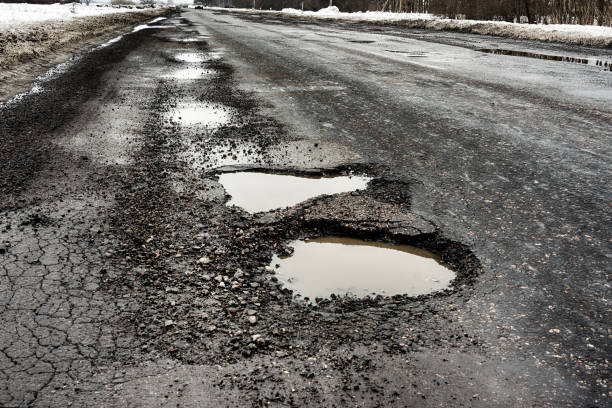

In [13]:
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded_images = files.upload()
if not uploaded_images:
    raise RuntimeError("No image was uploaded.")

image_name = next(iter(uploaded_images))
image_path = Path("/content") / image_name
image_path.write_bytes(uploaded_images[image_name])

prediction = best_model.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=320,
    device="cpu",
    verbose=False
)[0]

print("Image:", image_name)
print("Detections:", len(prediction.boxes))

for box in prediction.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())
    print(f"{best_model.names[class_id]} | confidence={confidence:.3f}")

display(Image.fromarray(prediction.plot()[:, :, ::-1]))

In [14]:
from google.colab import files

model_path = "/content/ROAD_GuardNet_CPU_Output/ROAD_GuardNet_FullData_Augmented/weights/best.pt"

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>